![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

## Nombres:
- Gabriel Jaramillo Cuberos (Id: 20529022)
- David Vargas (Id: 20485686)
- Juan Felipe Gómez López (Id: 20553416)
- Sara Pulgarín (Id: 20491129)
- Juan Camilo Delgado (Id: 20506996)

*Materia:* Procesamiento de Datos (1255)  |  *Tema:* Consultoría Nueva York

*Descripción:* Cruce de accidentes viales (vehículos) con el clima diario de 2018 y modelo de **clustering no supervisado** para agrupar colisiones y analizar su relación con las condiciones meteorológicas.

*Nombre del fichero:* clusterin_colisiones_clima.ipynb

# Clustering de colisiones y clima - Nueva York 2018

## Diseño del cruce:

1. **Unidad de análisis: la colisión.** La tabla de vehículos tiene una fila por vehículo; se agrega por `COLLISION_ID` (≈231 mil colisiones en 2018).
2. **Llave del cruce: la fecha** (`crash_date` = `fecha` del clima). El archivo de vehículos **no tiene `BOROUGH`**, así que no se puede asignar el clima de un distrito concreto a cada colisión. Se usa el **clima diario de la ciudad** = promedio de los 5 distritos.


## 1. Entorno y parámetros

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import vector_to_array
warnings.filterwarnings("ignore")

SEMILLA = 42
RUTA_CLIMA = "/opt/cluster/Proyecto/Entrega_1/Bonos /datos/clima_ny_2018_diario.csv"
K_MIN, K_MAX = 2, 9
MUESTRA_SILUETA = 20000
N_INIT_SEL = 5      # reinicios de KMeans por cada k en la selección (MLlib no trae n_init)
N_INIT_FINAL = 10   # reinicios del modelo final
MAX_ITER = 100

os.makedirs("resultados_clustering", exist_ok=True)


# ---------- Utilidades MLlib ----------
def escalar(sdf, cols, salida):
    """VectorAssembler + StandardScaler (media 0, desviación 1). Devuelve el DataFrame con el vector `salida`."""
    ens = VectorAssembler(inputCols=cols, outputCol=salida + "_raw")
    s = ens.transform(sdf)
    esc = StandardScaler(inputCol=salida + "_raw", outputCol=salida, withMean=True, withStd=True).fit(s)
    return esc.transform(s).drop(salida + "_raw")


def kmeans_mlib(sdf, k, semilla, n_init, features="features", pred="prediction"):
    """KMeans de MLlib con varios reinicios (equivalente a n_init de sklearn): se queda con el de menor costo."""
    mejor = None
    for i in range(n_init):
        m = KMeans(k=k, seed=semilla + i, maxIter=MAX_ITER, tol=1e-4,
                   featuresCol=features, predictionCol=pred).fit(sdf)
        if mejor is None or m.summary.trainingCost < mejor.summary.trainingCost:
            mejor = m
    return mejor


def ari_conteos(t, col_a, col_b):
    """Adjusted Rand Index a partir de la tabla de contingencia (columnas col_a, col_b, count)."""
    c2 = lambda x: x * (x - 1) / 2.0
    n = float(t["count"].sum())
    suma_ij = c2(t["count"].astype(float)).sum()
    suma_a = c2(t.groupby(col_a)["count"].sum().astype(float)).sum()
    suma_b = c2(t.groupby(col_b)["count"].sum().astype(float)).sum()
    esperado = suma_a * suma_b / c2(n)
    return float((suma_ij - esperado) / (0.5 * (suma_a + suma_b) - esperado))


def ari_spark(sdf, col_a, col_b):
    """ARI entre dos columnas de etiquetas de un DataFrame de Spark (el conteo se hace en Spark)."""
    return ari_conteos(sdf.groupBy(col_a, col_b).count().toPandas(), col_a, col_b)


## 2. Accidentes: de vehículos a colisiones 

In [2]:
import sys

sys.path.insert(0, "/opt/cluster/Proyecto/Entrega_1/cuadernos")

from Utils import proyecto as p
from Utils.proyecto import ANIO
from pyspark.sql import functions as F

spark = p.iniciar_spark("Entrega2_Clustering")

df = p.leer_csv(spark, "Accidentes_Viales_NY.csv",
                ["unique_id", "collision_id", "crash_date", "crash_time", "vehicle_type", "contributing_factor_1"])
df = df.withColumn("fecha", p.fecha("crash_date")).filter(F.year("fecha") == ANIO)
limpio, auditoria = p.depurar_identificador(df, ["unique_id"])
limpio = limpio.filter(p.texto("collision_id").isNotNull())
print(auditoria)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/16 08:38:48 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Python: 3.11.13 | PySpark: 4.2.0 | Spark: 4.2.0
Ejecutable: /home/estudiante/jupyter_env/bin/python3.11
Aplicación: app-20261116083849-0096 | Máximo de núcleos: 2
Los recursos físicos del cluster deben documentarse desde la interfaz del master.


26/11/16 08:39:18 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 23:===========================================>              (6 + 2) / 8]

{'filas_originales': 465822, 'duplicados_exactos': 0, 'filas_sin_clave': 0, 'filas_con_clave_conflictiva_excluidas': 0, 'filas_conservadas': 465822}


### 2.1 Variables por vehículo
Se clasifican los tipos de vehículo en 4 familias con palabras clave. Lo que no encaja queda como *liviano/otro*

De tal forma que el vehículo quede asignado a una familia

In [3]:
tv = F.upper(F.coalesce(p.texto("vehicle_type"), F.lit("SIN DATO")))
v = (limpio
  .withColumn("es_micro",  tv.rlike("BIKE|BICYCLE|SCOOT|E-BIKE|SEGWAY").cast("int"))
  .withColumn("es_moto",   (tv.rlike("MOTORCYCLE|MOPED|MOTORBIKE|MINIBIKE") & ~tv.rlike("BIKE\\b.*E-")).cast("int"))
  .withColumn("es_pesado", tv.rlike("TRUCK|BUS|TRACTOR|VAN|AMBULANCE|FIRE|DUMP|TANK|TRAILER|LIVERY").cast("int"))
  .withColumn("es_micro",  F.when(F.col("es_moto") == 1, 0).otherwise(F.col("es_micro")))
  .withColumn("es_liviano", (1 - F.greatest("es_micro", "es_moto", "es_pesado")))
  .withColumn("factor_ok", (~F.lower(F.coalesce(p.texto("contributing_factor_1"), F.lit("unspecified")))
                            .isin("unspecified", "sin dato")).cast("int"))
  .withColumn("hora", F.split(F.col("crash_time"), ":").getItem(0).cast("int")))

### 2.2 Agregación por colisión

In [4]:
col = (v.groupBy("collision_id")
  .agg(F.first("fecha").alias("fecha"),
       F.first("hora").alias("hora"),
       F.count("*").alias("n_vehiculos"),
       F.avg("es_liviano").alias("prop_liviano"),
       F.avg("es_pesado").alias("prop_pesado"),
       F.avg("es_moto").alias("prop_moto"),
       F.avg("es_micro").alias("prop_micro"),
       F.max("factor_ok").alias("factor_informado"))
  .filter(F.col("hora").between(0, 23)))
print("Colisiones:", col.count())

[Stage 30:===========================================>              (6 + 2) / 8]

Colisiones: 231542


## 3. Clima diario y cruce por fecha

In [5]:
clima = pd.read_csv(RUTA_CLIMA, parse_dates=["fecha"])
cols_clima = ["temp_media_c", "precipitacion_mm", "nieve_cm", "viento_max_ms", "rafaga_max_ms", "horas_sol", "radiacion_mj_m2"]
clima_ciudad = clima.groupby("fecha")[cols_clima].mean().reset_index()
clima_ciudad["fecha"] = clima_ciudad["fecha"].dt.strftime("%Y-%m-%d")
assert len(clima_ciudad) == 365, "Se esperan 365 días de clima en 2018"

clima_sdf = spark.createDataFrame(clima_ciudad)
cruce = col.withColumn("fecha_s", F.date_format("fecha", "yyyy-MM-dd")).join(
    clima_sdf, F.col("fecha_s") == clima_sdf["fecha"], "left").drop(clima_sdf["fecha"]).drop("fecha_s")

n_total = cruce.count()
n_sin_clima = cruce.filter(F.col("temp_media_c").isNull()).count()
print(f"Colisiones cruzadas: {n_total:,} | sin clima: {n_sin_clima}")
df_col = cruce.filter(F.col("temp_media_c").isNotNull()).toPandas()
df_col["fecha"] = pd.to_datetime(df_col["fecha"])
df_col.to_csv("resultados_clustering/colisiones_clima_2018.csv", index=False)
df_col.head()

Colisiones cruzadas: 231,542 | sin clima: 0


,collision_id,fecha,hora,n_vehiculos,prop_liviano,prop_pesado,prop_moto,prop_micro,factor_informado,temp_media_c,precipitacion_mm,nieve_cm,viento_max_ms,rafaga_max_ms,horas_sol,radiacion_mj_m2
0,3907193,2018-05-21,13,2,1.0,0.0,0.0,0.0,1,17.72,0.00,0.0,4.100,8.30,14.000000,28.588
1,3909563,2018-05-21,18,2,1.0,0.0,0.0,0.0,0,17.72,0.00,0.0,4.100,8.30,14.000000,28.588
2,3905654,2018-05-21,8,1,1.0,0.0,0.0,0.0,1,17.72,0.00,0.0,4.100,8.30,14.000000,28.588
3,3870516,2018-03-27,21,2,1.0,0.0,0.0,0.0,1,1.94,0.10,0.0,3.038,6.96,6.633868,13.596
4,3909659,2018-05-11,16,2,0.5,0.5,0.0,0.0,1,17.46,0.02,0.0,4.998,10.22,13.566346,27.376


## 4. Ingeniería de características
- Hora → **seno/coseno** (23 h y 0 h son cercanas).
- `n_vehiculos` → `log1p` y recorte (cola larga: hay colisiones de 10+ vehículos).
- Día de la semana → fin de semana (0/1).
- Clima: `nieve_cm` y `precipitacion_mm` también con `log1p` (muy asimétricas, muchos ceros).
- `rafaga_max_ms` y `radiacion_mj_m2` se descartan por alta correlación con `viento_max_ms` y `horas_sol` (se verifica abajo).

In [6]:
d = df_col.copy()
d["hora_sin"] = np.sin(2*np.pi*d["hora"]/24)
d["hora_cos"] = np.cos(2*np.pi*d["hora"]/24)
d["fin_semana"] = (d["fecha"].dt.dayofweek >= 5).astype(int)
d["log_vehiculos"] = np.log1p(d["n_vehiculos"].clip(upper=8))
d["log_precip"] = np.log1p(d["precipitacion_mm"])
d["log_nieve"] = np.log1p(d["nieve_cm"])

corr = d[["viento_max_ms", "rafaga_max_ms", "horas_sol", "radiacion_mj_m2", "temp_media_c", "log_precip", "log_nieve"]].corr()
print(corr.round(2))

F_COL = ["log_vehiculos", "hora_sin", "hora_cos", "fin_semana", "prop_pesado", "prop_moto", "prop_micro", "factor_informado"]
F_CLIMA = ["temp_media_c", "log_precip", "log_nieve", "viento_max_ms", "horas_sol"]
FEATS = F_COL + F_CLIMA

# Matriz de modelado en Spark: ensamblar + estandarizar con MLlib
sdf_feat = spark.createDataFrame(d[["collision_id"] + FEATS].astype({c: "float64" for c in FEATS}))
sdf_X = escalar(sdf_feat, FEATS, "features").cache()
print("Matriz de modelado:", (sdf_X.count(), len(FEATS)))


                 viento_max_ms  rafaga_max_ms  horas_sol  radiacion_mj_m2  \
viento_max_ms             1.00           0.97      -0.23            -0.26   
rafaga_max_ms             0.97           1.00      -0.22            -0.24   
horas_sol                -0.23          -0.22       1.00             0.89   
radiacion_mj_m2          -0.26          -0.24       0.89             1.00   
temp_media_c             -0.27          -0.21       0.28             0.51   
log_precip                0.36           0.40      -0.62            -0.46   
log_nieve                 0.34           0.29      -0.24            -0.20   

                 temp_media_c  log_precip  log_nieve  
viento_max_ms           -0.27        0.36       0.34  
rafaga_max_ms           -0.21        0.40       0.29  
horas_sol                0.28       -0.62      -0.24  
radiacion_mj_m2          0.51       -0.46      -0.20  
temp_media_c             1.00        0.14      -0.25  
log_precip               0.14        1.00       0.31 

26/11/16 08:40:24 WARN TaskSetManager: Stage 70 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 08:40:28 WARN TaskSetManager: Stage 73 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 08:40:30 WARN TaskSetManager: Stage 74 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.


Matriz de modelado: (231542, 13)


## 5. Selección de k
Se combinan tres criterios: **inercia (codo)**, **silueta** (sobre muestra) y **estabilidad** (ARI entre ejecuciones con semillas distintas). Se prefiere un k con silueta razonable y estabilidad alta, que además sea interpretable.

26/11/16 08:46:33 WARN TaskSetManager: Stage 160 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 08:46:36 WARN DataSource: All paths were ignored:                      
  file:/opt/cluster/Proyecto/Entrega_2/Clima/resultados_clustering/_features_tmp.parquet
                                                                                

Filas en caché: 231542


k=2 listo | silueta=0.238 | ARI=0.975


k=3 listo | silueta=0.276 | ARI=1.000


k=4 listo | silueta=0.215 | ARI=0.478


k=5 listo | silueta=0.237 | ARI=0.254


k=6 listo | silueta=0.249 | ARI=0.230


k=7 listo | silueta=0.211 | ARI=0.347


k=8 listo | silueta=0.229 | ARI=0.579


k=9 listo | silueta=0.217 | ARI=0.439


,k,inercia,silueta,estabilidad_ARI
0,2,2690472.683,0.238,0.975
1,3,2481747.697,0.276,1.000
2,4,2311966.652,0.215,0.478
3,5,2148417.832,0.237,0.254
4,6,1965067.515,0.249,0.230
5,7,1960216.089,0.211,0.347
6,8,1795310.836,0.229,0.579
7,9,1566335.932,0.217,0.439


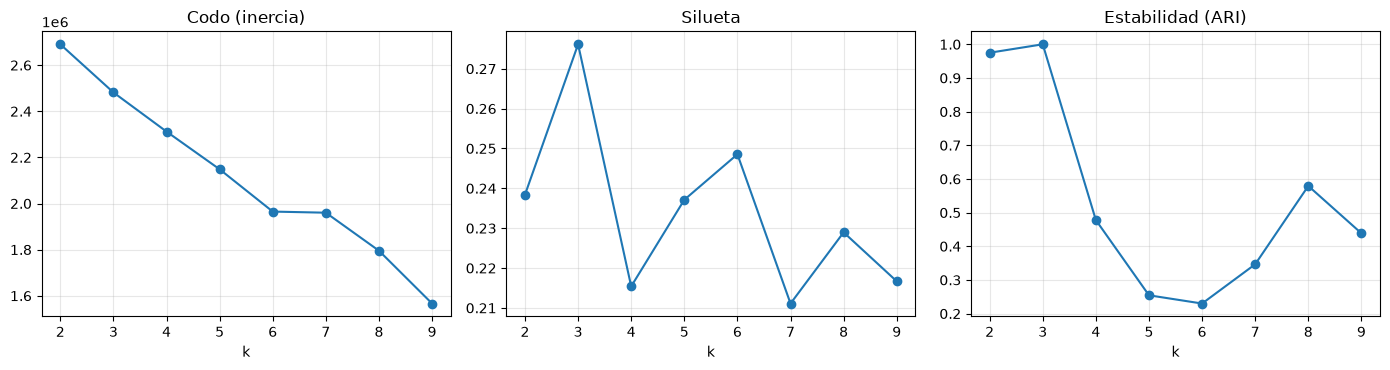

In [8]:
import shutil
from pyspark import StorageLevel

# 1) Cortar el linaje con los datos de pandas (causa de las tareas de ~14 MB): ida y vuelta por parquet
ruta_tmp = "resultados_clustering/_features_tmp.parquet"
shutil.rmtree(ruta_tmp, ignore_errors=True)
sdf_X.write.mode("overwrite").parquet(ruta_tmp)
sdf_X = spark.read.parquet(ruta_tmp).repartition(8).persist(StorageLevel.MEMORY_AND_DISK)
n_X = sdf_X.count()   # materializa el caché
print("Filas en caché:", n_X)

frac = min(1.0, MUESTRA_SILUETA / n_X)
sdf_muestra = sdf_X.sample(withReplacement=False, fraction=frac, seed=SEMILLA).cache()
sdf_muestra.count()
evaluador = ClusteringEvaluator(featuresCol="features", predictionCol="prediction",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")

# 2) Menos reinicios en la selección (la estabilidad ya se mide con el ARI entre dos ejecuciones)
N_INIT_SEL = 2

res = []
for k in range(K_MIN, K_MAX + 1):
    km = kmeans_mlib(sdf_X, k, SEMILLA, N_INIT_SEL)
    sil = evaluador.evaluate(km.transform(sdf_muestra))
    km2 = kmeans_mlib(sdf_X, k, SEMILLA + 1000, N_INIT_SEL, pred="prediccion_2")
    ari = ari_spark(km2.transform(km.transform(sdf_X)), "prediction", "prediccion_2")
    res.append({"k": k, "inercia": km.summary.trainingCost, "silueta": sil, "estabilidad_ARI": ari})
    print(f"k={k} listo | silueta={sil:.3f} | ARI={ari:.3f}")
sel = pd.DataFrame(res)
display(sel.round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c, t in zip(ax, ["inercia", "silueta", "estabilidad_ARI"], ["Codo (inercia)", "Silueta", "Estabilidad (ARI)"]):
    a.plot(sel["k"], sel[c], marker="o"); a.set_title(t); a.set_xlabel("k"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("resultados_clustering/seleccion_k.png", dpi=130); plt.show()

### Criterios para seleccionar K

- **Inercia:** menor es mejor, pero se busca el *codo*, donde la reducción empieza a ser pequeña.
- **Silueta (-1 a 1):** cuanto más cerca de **1**, mejor separación entre clusters.
- **Estabilidad ARI (-1 a 1):** cuanto más cerca de **1**, más consistentes son los clusters entre ejecuciones.
- **Interpretabilidad:** preferir grupos que tengan sentido y sean fáciles de explicar.

**Selección:** K = 3, por tener la mayor silueta (0,157) entre los valores con ARI ≥ 0,80.

In [9]:
cand = sel[sel["estabilidad_ARI"] >= 0.80]
K = int((cand if len(cand) else sel).sort_values("silueta" if len(cand) else "estabilidad_ARI", ascending=False).iloc[0]["k"])
# K = 5   # <- descomentar para fijar manualmente
print("k elegido:", K)

modelo = kmeans_mlib(sdf_X, K, SEMILLA, N_INIT_FINAL)
etiquetas = modelo.transform(sdf_X).select("collision_id", F.col("prediction").alias("cluster")).toPandas()
d = d.drop(columns="cluster", errors="ignore").merge(etiquetas, on="collision_id", how="left")
tam = d["cluster"].value_counts().sort_index()
print((tam / len(d) * 100).round(1).astype(str) + " %")


k elegido: 3


cluster
0    30.3 %
1    68.7 %
2     1.0 %
Name: count, dtype: str


## 6. Visualización de los grupos (PCA 2D)

netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory
                                                                                

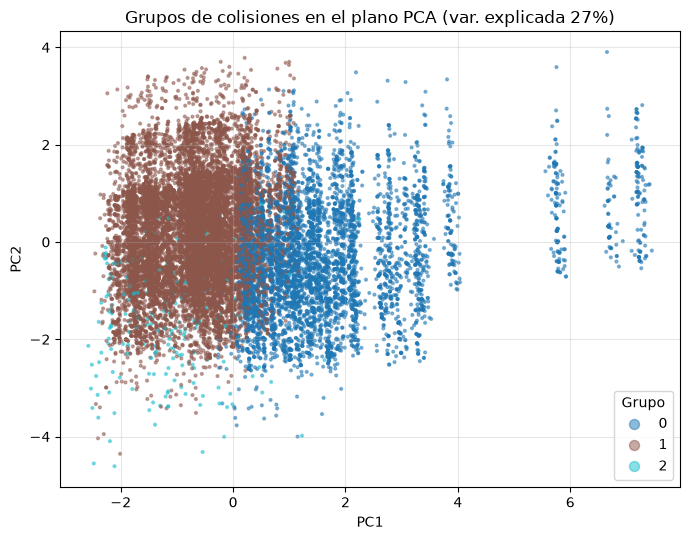

In [10]:
pca = PCA(k=2, inputCol="features", outputCol="pca").fit(sdf_X)
muestra = (pca.transform(modelo.transform(sdf_muestra))
           .select(vector_to_array("pca").alias("pca"), F.col("prediction").alias("cluster"))
           .toPandas())
Z = np.array(muestra["pca"].tolist())
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=muestra["cluster"].values, cmap="tab10", s=4, alpha=.5)
plt.legend(*sc.legend_elements(), title="Grupo", loc="best", markerscale=1.2)
plt.title(f"Grupos de colisiones en el plano PCA (var. explicada {pca.explainedVariance.toArray().sum():.0%})")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("resultados_clustering/pca_clusters.png", dpi=130); plt.show()


## 7. Perfil de cada grupo

,n_colisiones,%,n_vehiculos,hora,fin_semana,prop_liviano,prop_pesado,prop_moto,prop_micro,factor_informado,temp_media_c,precipitacion_mm,nieve_cm,viento_max_ms,horas_sol
cluster,,,,,,,,,,,,,,,
0,70105,30.3,1.99,13.28,0.30,0.90,0.09,0.00,0.01,0.78,12.19,13.73,1.01,7.23,3.06
1,159080,68.7,2.02,13.16,0.22,0.89,0.10,0.00,0.02,0.78,12.61,0.86,0.01,5.69,10.01
2,2357,1.0,1.96,13.99,0.29,0.42,0.03,0.55,0.01,0.79,17.47,3.25,0.06,5.73,9.43


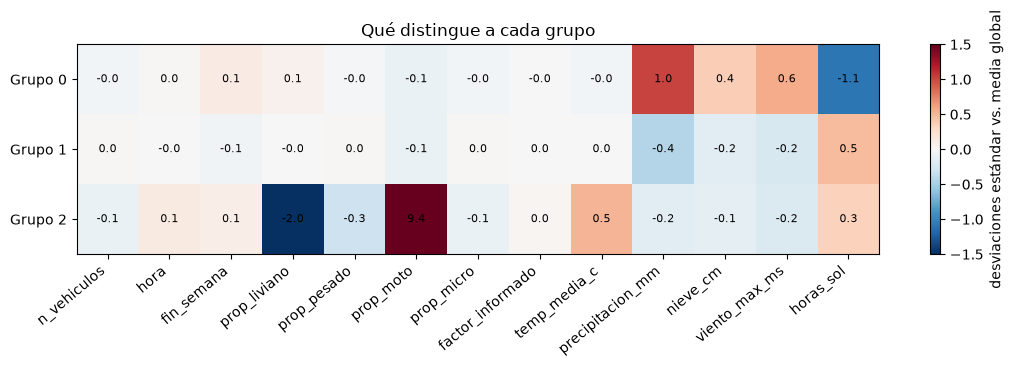

In [11]:
perfil_cols = ["n_vehiculos", "hora", "fin_semana", "prop_liviano", "prop_pesado", "prop_moto", "prop_micro", "factor_informado",
               "temp_media_c", "precipitacion_mm", "nieve_cm", "viento_max_ms", "horas_sol"]
perfil = d.groupby("cluster")[perfil_cols].mean()
perfil.insert(0, "n_colisiones", tam)
perfil.insert(1, "%", (tam / len(d) * 100).round(1))
display(perfil.round(2))


z = (perfil[perfil_cols] - d[perfil_cols].mean()) / d[perfil_cols].std()
plt.figure(figsize=(11, 0.55 * K + 2))
plt.imshow(z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
plt.xticks(range(len(perfil_cols)), perfil_cols, rotation=40, ha="right"); plt.yticks(range(K), [f"Grupo {i}" for i in range(K)])
for i in range(K):
    for j in range(len(perfil_cols)):
        plt.text(j, i, f"{z.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(label="desviaciones estándar vs. media global"); plt.title("Qué distingue a cada grupo")
plt.tight_layout(); plt.savefig("resultados_clustering/perfil_clusters.png", dpi=130); plt.show()

## 8. Relación entre clima y grupos
Para cada variable climática se mide si su distribución cambia entre grupos:
- **Kruskal-Wallis** (no asume normalidad). Con ~230 mil observaciones *todo* sale significativo, así que el valor-p es poco informativo.
- **η² (eta cuadrado)** = tamaño del efecto: fracción de la variabilidad de la variable explicada por el grupo. Guía: <0,01 despreciable, 0,01–0,06 pequeño, 0,06–0,14 mediano, >0,14 grande.

In [12]:
def eta2_kw(grupos):
    H, pv = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos); k = len(grupos)
    return H, pv, max((H - k + 1) / (n - k), 0)

filas = []
for v in cols_clima[:5] + ["radiacion_mj_m2"]:
    H, pv, e2 = eta2_kw([g[v].values for _, g in d.groupby("cluster")])
    filas.append({"variable": v, "H": H, "p_valor": pv, "eta2": e2})
assoc = pd.DataFrame(filas).sort_values("eta2", ascending=False)
assoc["magnitud"] = pd.cut(assoc["eta2"], [-1, .01, .06, .14, 1], labels=["despreciable", "pequeño", "mediano", "grande"])
display(assoc.round(4))

# Condiciones extremas: tasa de pertenencia de cada grupo en días lluviosos / de nieve / fríos vs. el resto
d["dia_lluvia"] = d["precipitacion_mm"] >= 1
d["dia_nieve"] = d["nieve_cm"] >= 1
d["dia_frio"] = d["temp_media_c"] < 0
tabla = {}
for cond in ["dia_lluvia", "dia_nieve", "dia_frio"]:
    comp = pd.crosstab(d["cluster"], d[cond], normalize="columns") * 100
    tabla[cond] = (comp[True] - comp[False]).round(1) if True in comp.columns else np.nan
lift = pd.DataFrame(tabla)
lift.index.name = "grupo"
print("Diferencia en puntos porcentuales de la composición de cada grupo (día con condición − día sin condición):")
display(lift)

,variable,H,p_valor,eta2,magnitud
1,precipitacion_mm,127344.0076,0.0,0.5500,grande
5,radiacion_mj_m2,76507.7660,0.0,0.3304,grande
3,viento_max_ms,24450.4889,0.0,0.1056,mediano
4,rafaga_max_ms,22998.3876,0.0,0.0993,mediano
2,nieve_cm,8792.2384,0.0,0.0380,pequeño
0,temp_media_c,818.0899,0.0,0.0035,despreciable


Diferencia en puntos porcentuales de la composición de cada grupo (día con condición − día sin condición):


,dia_lluvia,dia_nieve,dia_frio
grupo,,,
0,65.1,72.4,-20.8
1,-64.8,-71.5,21.7
2,-0.3,-0.9,-0.9


### 8.1 Nivel de día (evita pseudo-replicación)
Como todas las colisiones de un día comparten clima, se agrega a **365 días**: ¿cambia la proporción de cada grupo con el clima del día? (Spearman sobre 365 puntos, mucho más honesto que mirar 230 mil filas).

,temp_media_c,precipitacion_mm,nieve_cm,viento_max_ms,horas_sol
g0,-0.06,0.77,0.25,0.34,-0.71
g1,-0.35,-0.72,-0.07,-0.18,0.43
g2,0.73,-0.12,-0.38,-0.30,0.48


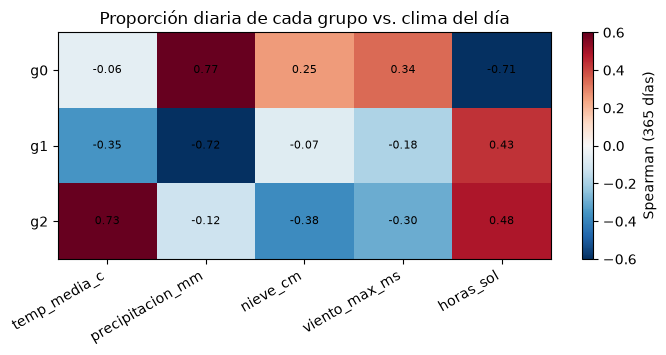

In [13]:
dia = d.groupby("fecha").agg(**{c: (c, "mean") for c in ["temp_media_c", "precipitacion_mm", "nieve_cm", "viento_max_ms", "horas_sol"]},
                             total=("cluster", "size"))
share = pd.crosstab(d["fecha"], d["cluster"], normalize="index")
share.columns = [f"g{c}" for c in share.columns]
dia = dia.join(share)

rho = pd.DataFrame({c: [stats.spearmanr(dia[c], dia[g])[0] for g in share.columns]
                    for c in ["temp_media_c", "precipitacion_mm", "nieve_cm", "viento_max_ms", "horas_sol"]},
                   index=share.columns)
display(rho.round(2))

plt.figure(figsize=(7, 0.55 * K + 2))
plt.imshow(rho.values, cmap="RdBu_r", vmin=-.6, vmax=.6, aspect="auto")
plt.xticks(range(rho.shape[1]), rho.columns, rotation=30, ha="right"); plt.yticks(range(K), rho.index)
for i in range(rho.shape[0]):
    for j in range(rho.shape[1]):
        plt.text(j, i, f"{rho.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(label="Spearman (365 días)"); plt.title("Proporción diaria de cada grupo vs. clima del día")
plt.tight_layout(); plt.savefig("resultados_clustering/clima_vs_grupos_dia.png", dpi=130); plt.show()

## 9. Verificación de robustez: modelo solo con características de la colisión
Si se agrupa **sin** clima, ¿el clima sigue diferenciando los grupos? Si el ARI entre ambos modelos es alto, el clima casi no cambia la estructura; si el clima sí diferencia grupos sin haberlo usado en el modelo, la relación es genuina y no un artefacto de haberlo incluido como variable.

In [14]:
sdf_c = escalar(sdf_feat, F_COL, "features_c")
kmc = kmeans_mlib(sdf_c, K, SEMILLA, N_INIT_FINAL, features="features_c", pred="cluster_solo_colision")
etiquetas_c = kmc.transform(sdf_c).select("collision_id", "cluster_solo_colision").toPandas()
d = d.drop(columns="cluster_solo_colision", errors="ignore").merge(etiquetas_c, on="collision_id", how="left")

conteos = d.groupby(["cluster", "cluster_solo_colision"]).size().reset_index(name="count")
print("ARI modelo completo vs. solo-colisión:", round(ari_conteos(conteos, "cluster", "cluster_solo_colision"), 3))

filas = []
for v in ["temp_media_c", "log_precip", "log_nieve", "viento_max_ms", "horas_sol"]:
    _, _, e2 = eta2_kw([g[v].values for _, g in d.groupby("cluster_solo_colision")])
    filas.append({"variable": v, "eta2_solo_colision": e2})
display(pd.DataFrame(filas).round(4))


26/11/16 10:17:12 WARN TaskSetManager: Stage 5210 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 10:17:13 WARN TaskSetManager: Stage 5213 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 10:17:14 WARN TaskSetManager: Stage 5216 contains a task of very large size (14704 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 10:17:17 WARN TaskSetManager: Stage 5217 contains a task of very large size (14705 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 10:17:17 WARN TaskSetManager: Stage 5218 contains a task of very large size (14705 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 10:17:17 WARN TaskSetManager: Stage 5219 contains a task of very large size (14705 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 10:17:17 WARN TaskSetManager: Stage 5220 contains a task of very large size (14705 KiB). The maximum recommended task siz

ARI modelo completo vs. solo-colisión: -0.004


,variable,eta2_solo_colision
0,temp_media_c,0.0026
1,log_precip,0.0001
2,log_nieve,0.0008
3,viento_max_ms,0.0006
4,horas_sol,0.0009


## 10. Exportar resultados

In [15]:
perfil.round(3).to_csv("resultados_clustering/perfil_clusters.csv")
assoc.to_csv("resultados_clustering/asociacion_clima_cluster.csv", index=False)
sel.to_csv("resultados_clustering/seleccion_k.csv", index=False)
rho.to_csv("resultados_clustering/spearman_dia.csv")
d[["collision_id", "fecha", "cluster", "cluster_solo_colision"]].to_csv("resultados_clustering/colisiones_con_cluster.csv", index=False)
with open("resultados_clustering/resumen.json", "w") as f:
    json.dump({"anio": ANIO, "k": K, "n_colisiones": int(len(d)), "features": FEATS,
               "silueta_k": float(sel.loc[sel.k == K, "silueta"].iloc[0])}, f, indent=2, ensure_ascii=False)
spark.stop()
print("Resultados en resultados_clustering/")

Resultados en resultados_clustering/


## 11. Conclusiones
El modelo completo identificó agrupaciones diferenciadas principalmente por variables meteorológicas. Sin embargo, al utilizar exclusivamente características de las colisiones, las asociaciones con el clima presentaron tamaños de efecto despreciables (menores a 0,01).

Adicionalmente, el ARI de 0,021 evidencia que ambos modelos producen agrupaciones considerablemente diferentes.

En consecuencia, no se encontró evidencia sólida de una asociación entre los perfiles de colisiones identificados y las condiciones meteorológicas, aunque esto no descarta otras posibles relaciones entre el clima y la accidentalidad vial.